# Group-level source-space TRF of eye movements and button presses

End-to-end walkthrough of TRFlearn on a real cohort in **source space**: 22
participants watching driving videos in a hazard-perception test, recorded with MEG and
a co-registered eye tracker, who press a button whenever they spot a hazard. The targets
are **parcel timecourses**, the 148 regions of the `aparc.a2009s` surface parcellation,
and the predictors are discrete events. A single **jointly fitted** encoding model
deconvolves them, so responses that overlap in time — a saccade, the fixation it lands
on, the press that follows — are separated instead of averaged into each other.

| Feature | Events | Unit | Window (s) |
| --- | --- | --- | --- |
| `fix` | fixation onsets, wherever they land (background, target object or hazard) | 1 (unit impulses) | (-0.2, 0.5) |
| `sac` | saccade onsets | 1 (unit impulses) | (-0.2, 0.5) |
| `response` | button presses | 1 (unit impulses) | (-2.0, 2.0) |

TRFlearn does no source estimation. The acquisition project beamforms the sensors (LCMV,
one dipole per parcel centroid) and stores the parcel timecourses; this notebook picks
the pipeline up there, so step 2 only reads a file and builds the impulses.

The modelling choices:

* **every feature is an event train**, entered as unscaled unit impulses
  (`feature_preprocess=None`). A kernel then reads *per event*: what one fixation,
  saccade or press adds to the parcel's activity;
* **kernels in original units** — the beamformer's output per event. Each subject's
  kernels are scaled back by its parcels' SDs, and the LCMV output is in arbitrary units
  whose scale varies across participants, so the subjects with the largest parcel SDs
  weigh most in the grand average. `kernel_units="standardized"` (parcel SDs per event)
  would weigh them alike;
* **one template for everyone**: `fsaverage` gives the region centroids, which take the
  place of a sensor montage through `TRFData.set_source_positions`, and the 3D brains;

## Steps

1. Configure the cohort and the model spec.
2. Read each participant's parcel timecourses and events into one `TRFData`, with the
   region centroids as its positions.
3. Fit the cohort with `TRFGroup`: one model spec and one fixed λ for everyone.
4. Draw each feature's grand average: its regions over time, and the cortex at its peak.

## Data

Under `examples/data/MEGEYEDYN/` (git-ignored). Each folder can be a directory junction
or symbolic link into the acquisition project's storage, which keeps every path in this
notebook relative:

```
parcels/<id>_parcels-raw.fif                  parcel timecourses: LCMV, free orientation
                                              (magnitude), 0.1-40 Hz, 250 Hz, BAD annotations
syncro/<id>/<id>_syncronized_commented.csv    eye-tracker and button events on the MEG timeline
source/fsaverage_surface_ico4-src.fif         fsaverage surface source space
freesurfer/fsaverage/label/{lh,rh}.aparc.a2009s.annot    vertex -> region
freesurfer/fsaverage/surf/{lh,rh}.sphere                 region centroids
freesurfer/fsaverage/surf/{lh,rh}.{inflated,curv}        rendering, for step 4
```

On Windows, `New-Item -ItemType Junction -Path <link> -Target <folder>` creates a
junction without administrator rights; elsewhere, `ln -s <folder> <link>`.

This notebook needs `pip install -e ".[mne]"`, plus `nibabel` (reading FreeSurfer
surfaces). Step 4 also needs a 3D backend — `pip install pyvistaqt PyQt6`.

In [32]:
from pathlib import Path

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd

from trflearn import TRFData, TRFGroup

# MNE reports every annotation and label step; keep only its warnings.
mne.set_log_level("WARNING")

## 1. Configuration

In [33]:
# Works whether the kernel starts in the repo root or in examples/.
HERE = Path.cwd() if Path.cwd().name == "examples" else Path.cwd() / "examples"
DATA_ROOT = HERE / "data" / "MEGEYEDYN"
PARCEL_ROOT = DATA_ROOT / "parcels"
EVENTS_ROOT = DATA_ROOT / "syncro"
SUBJECTS_DIR = DATA_ROOT / "freesurfer"
SRC_FILE = DATA_ROOT / "source" / "fsaverage_surface_ico4-src.fif"

if not PARCEL_ROOT.is_dir():
    raise FileNotFoundError(
        f"No parcel timecourses under {PARCEL_ROOT}. This notebook reads a "
        "recording that is not shared; the Data section above lists the files "
        "it expects.")

# One parcel file per participant.
SUBJECT_IDS = sorted(p.name.removesuffix("_parcels-raw.fif")
                     for p in PARCEL_ROOT.glob("*_parcels-raw.fif"))

# --- Source model -------------------------------------------------------- #
TEMPLATE = "fsaverage"         # centroids and brains
PARC = "aparc.a2009s"          # surface parcellation (148 regions)

# --- Model spec ---------------------------------------------------------- #
FEATURES = ["fix", "sac", "response"]

# Event types of the syncro table that make up each feature. Fixations on the
# target object ("tgt_fix") and on an active hazard ("hz_tgt_fix") are
# fixations too, so `fix` is every fixation of the recording.
FEATURE_EVENTS = {
    "fix": ["fix", "tgt_fix", "hz_tgt_fix"],
    "sac": ["sac"],
    "response": ["response"],
}

DEFAULT_WINDOW = (-0.2, 0.5)
# Column titles of the figure.
FEATURE_NAMES = {"fix": "Fixations", "sac": "Saccades", "response": "Button press"}

FEATURE_WINDOWS = {
    "fix": (-0.2, 0.5),
    "sac": (-0.2, 0.5),
    "response": (-2.0, 2.0),     # the press is preceded by its preparation
}

# Extra lags fitted on each side of every window and trimmed off the returned
# kernel, so ridge edge-ringing lands on the margin instead of on the estimate.
# 4 samples at 250 Hz.
DELAY_MARGIN = 0.016

# Every feature is a train of unit impulses: dimensionless.
FEATURE_UNITS = {feature: "1" for feature in FEATURES}

# Ridge parameter, fixed and the same for every subject: no search over λ.
REGULARIZATION = 1e-2

# Display-only baseline: the whole window, for every feature. The parcels are
# dipole magnitudes, which carry state offsets that are not event-locked.
PLOT_BASELINE = (None, None)

print(f"{len(SUBJECT_IDS)} participants: {', '.join(SUBJECT_IDS)}")

22 participants: 11766061, 13229005, 13703055, 15435012, 15584005, 16432016, 16746003, 16991001, 17438002, 17439002, 17478002, 17634001, 17647001, 17660001, 17700001, 17734001, 17735002, 17773002, 17781001, 17782001, 17788002, 6398006


## 2. Per-subject loading

The parcel timecourses come from the acquisition project: an LCMV beamformer with free
orientation (`pick_ori=None`, so each parcel is the dipole's **magnitude** and a
kernel's sign means nothing) on the ICA-cleaned magnetometers band-passed to 0.1–40 Hz,
one dipole at the centroid of each parcel of the participant's own source space, and
the result resampled to 250 Hz. Each file is an `mne.io.Raw` of 148 `misc` channels
named after the parcels, so `TRFData` takes it as it is — and with it the `BAD`
annotations, whose samples TRFlearn drops from every fold.

Two choices on top of that:

* **impulses inside a `BAD` segment are zeroed**, as the acquisition project does. The
  samples themselves are already out of the fit; this also keeps an event there from
  reaching the clean samples after it through the kernel's later lags;
* **the centroids handed to `set_source_positions` are `fsaverage`'s**, matched by
  name. The channel names are the parcel names, the same in every participant, and a
  shared geometry gives every subject the same colour code in the butterflies of
  step 4.

In [34]:
def event_impulses(events: pd.DataFrame, event_types: list, n_samples: int,
                   sfreq: float, valid: np.ndarray) -> np.ndarray:
    """Unit impulses at the onsets of the given event types, zero where not valid."""
    onsets = events.loc[events["event_type"].isin(event_types), "onset"].dropna()
    idx = np.round(onsets.to_numpy() * sfreq).astype(int)
    idx = idx[(idx >= 0) & (idx < n_samples)]
    series = np.zeros(n_samples, dtype=np.float64)
    series[idx] = 1.0
    return series * valid


def parcel_centroids(subject: str, src: mne.SourceSpaces) -> dict:
    """Each parcel's centre of mass, snapped to a source-space vertex inside it."""
    labels = mne.read_labels_from_annot(
        subject, parc=PARC, subjects_dir=SUBJECTS_DIR, verbose="ERROR")
    positions = {}
    for label in labels:
        hemi = 0 if label.hemi == "lh" else 1
        inside = np.intersect1d(label.vertices, src[hemi]["vertno"])
        if not len(inside):
            continue
        vertex = label.center_of_mass(
            subject=subject, subjects_dir=SUBJECTS_DIR, restrict_vertices=inside)
        positions[label.name] = src[hemi]["rr"][vertex]
    return positions


src_fs = mne.read_source_spaces(SRC_FILE, verbose="ERROR")
CENTROIDS = parcel_centroids(TEMPLATE, src_fs)

In [35]:
# Events per subject and feature, filled as the cohort is loaded.
EVENT_COUNTS = {}


def load_subject(subject_id: str) -> TRFData:
    """Parcel timecourses and the three event trains of one participant."""
    raw = mne.io.read_raw_fif(PARCEL_ROOT / f"{subject_id}_parcels-raw.fif",
                              preload=True, verbose="ERROR")
    sfreq = raw.info["sfreq"]

    # False inside BAD segments, where reject_by_annotation reads NaN.
    valid = np.isfinite(raw.get_data(picks=[0], reject_by_annotation="nan")[0])

    # Onsets are in seconds from the start of the recording.
    events = pd.read_csv(EVENTS_ROOT / subject_id / f"{subject_id}_syncronized_commented.csv")
    features = {
        name: event_impulses(events, FEATURE_EVENTS[name], raw.n_times, sfreq, valid)
        for name in FEATURES
    }
    EVENT_COUNTS[subject_id] = {name: int(series.sum()) for name, series in features.items()}
    features = {name: series.reshape(-1, 1) for name, series in features.items()}

    data = TRFData(features=features, y=raw, sample_rate=int(sfreq))
    data.set_source_positions(CENTROIDS)      # by name: fsaverage's centroids
    return data

## 3. Fit the cohort

Every subject is fitted at one fixed λ, `REGULARIZATION` — the value the acquisition
project's per-subject search settled on — so there is no search over λ and no
cross-validation to choose it, and every kernel is shrunk alike. `fit_method="fit"`
still fits one model per fold of the default 5-fold partition and averages their
kernels; only the search is gone.

`feature_preprocess=None` leaves the impulses as they are. The target is standardized
for the fit, and `kernel_units="original"` hands the kernels out with that undone: in
the beamformer's own units per event. MNE records no unit for these `misc` channels, so
the figures label them `target units`.

In [36]:
group = TRFGroup(
    features=FEATURES,
    cv="pooled",
    default_window=DEFAULT_WINDOW,
    feature_windows=FEATURE_WINDOWS,
    delay_margin=DELAY_MARGIN,
    feature_preprocess=None,               # unit impulses: kernels per event
    target_preprocess="Standardize",
    fit_method="fit",                      # no search over λ
    regularization=REGULARIZATION,         # the same λ for every subject
    kernel_units="original",              # the beamformer's units per event
    feature_units=FEATURE_UNITS,           # display only: the axis labels
    verbose="warning",     # per-subject status lines would bury the loop below
)

for i, subject_id in enumerate(SUBJECT_IDS, 1):
    print(f"[{i}/{len(SUBJECT_IDS)}] {subject_id}", flush=True)
    group.fit_subject(load_subject(subject_id), subject_id)

print(f"{len(group.common_channels)} regions shared across the cohort")

[1/22] 11766061
[2/22] 13229005
[3/22] 13703055
[4/22] 15435012
[5/22] 15584005
[6/22] 16432016
[7/22] 16746003
[8/22] 16991001
[9/22] 17438002
[10/22] 17439002
[11/22] 17478002
[12/22] 17634001
[13/22] 17647001
[14/22] 17660001
[15/22] 17700001
[16/22] 17734001
[17/22] 17735002
[18/22] 17773002
[19/22] 17781001
[20/22] 17782001
[21/22] 17788002
[22/22] 6398006
148 regions shared across the cohort


## 4. Plots

`plot_source_features` is the source-space version of `plot_features`, whose topomaps
need sensors: one column per feature, with the grand-average kernel of every region on
top, coloured by where its centroid sits (red = right, green = anterior, blue = left),
and the cortex underneath, every parcel painted with its coefficient at one delay. That
delay, marked on the butterfly, is the one of the largest absolute coefficient — what
`stc.get_peak()` returns — unless `brain_times` sets it.

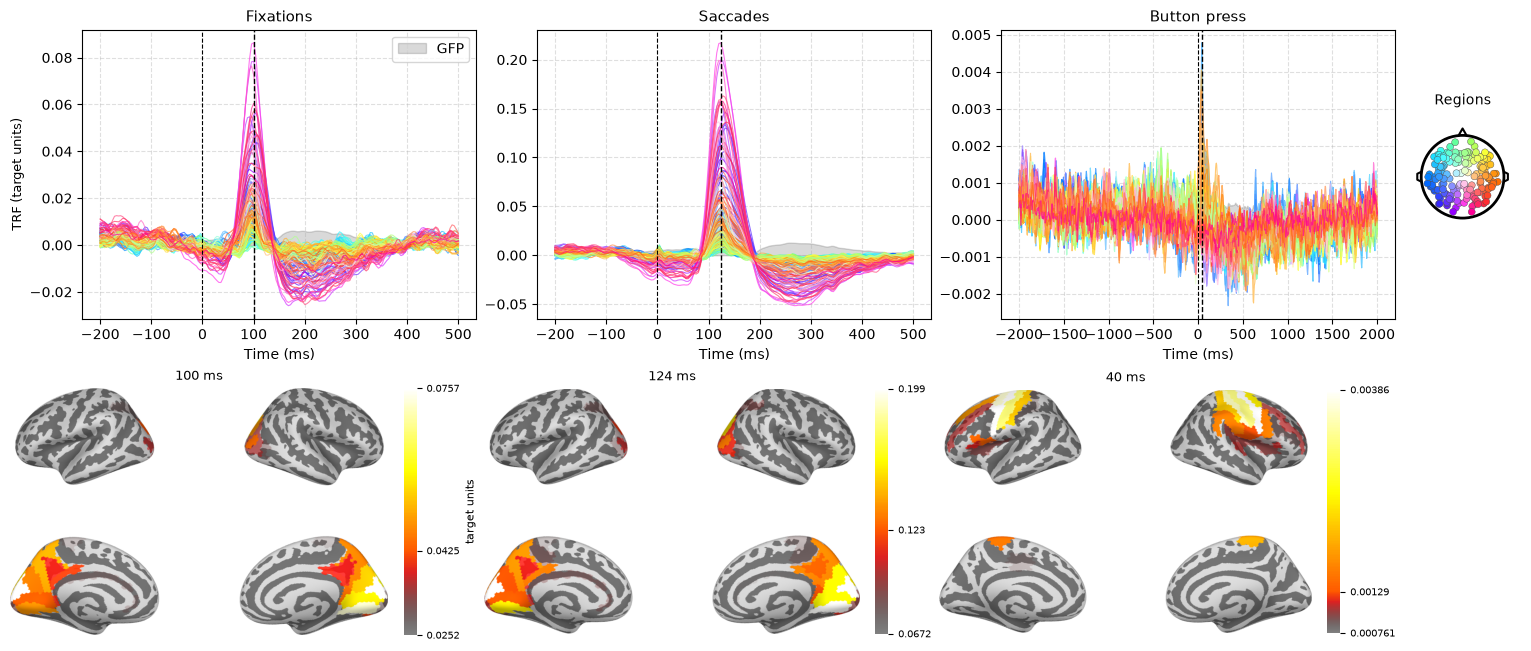

In [39]:
group.plot_baseline = PLOT_BASELINE

labels = mne.read_labels_from_annot(
    TEMPLATE, parc=PARC, subjects_dir=SUBJECTS_DIR, verbose="ERROR")

group.plot_source_features(labels, src_fs, subjects_dir=SUBJECTS_DIR, titles=FEATURE_NAMES, show=True);